In [9]:
import numpy as np
import matplotlib.pyplot as plt


Question-1 
part 1.1 and 1.2

To find the roots of an algebraic equation f(x) = 0 with a root at x*, the fixed-point iteration method reformulates the problem into x =
g(x). Starting from an initial guess x(0), successive approximations are generated by:
x(k) = g(x(k-1))
Convergence occurs if |g'(x*)| < 1 in a neighborhood of x*. If |g'(x*)| > 1, the sequence diverges away from x* (repelling fixed point).

In [29]:
def fixed_point_iteration(g, x0, tol=1e-10, max_iter=100):
    """Return the final estimate, iteration history, and convergence status."""
    x = float(x0)
    history = [x]

    for _ in range(max_iter):
        x_next = float(g(x))
        if not np.isfinite(x_next):
            return x_next, history, False

        history.append(x_next)
        if abs(x_next - x) < tol:
            return x_next, history, True
        x = x_next

    return x, history, False


def f(x):
    return (x - 1) * (x - 2)


def g(x):
    return x + f(x)


root, history, converged = fixed_point_iteration(g, x0=0.8)
print(f"Estimate: {root}, converged: {converged}")

Estimate: 1.0, converged: True


part 1.3 and 1.4

We consider f(x) = (x-1)(x-2) = x2 - 3x + 2. Its analytic derivative is f'(x) = 2x - 3. The most obvious fixed-point conversion is defined as:
g1(x) = f(x) + x = x2 - 2x + 2
Proof of Root Equivalence: Setting g1(x) = x ⇔ f(x) + x = x ⇔ f(x) = 0. Thus, the roots of f(x) = 0 and the fixed points of g1(x) = x are
identical: x* ∈ {1, 2}.

In [30]:
def f_q1(x):
    """Evaluates f(x) = (x - 1)(x - 2) = x^2 - 3x + 2."""
    return (x - 1.0) * (x - 2.0)

def df_q1(x):
    """Analytic derivative f'(x) = 2x - 3."""
    return 2.0 * x - 3.0

def g1(x):
    """Obvious conversion g1(x) = f(x) + x = x^2 - 2x + 2."""
    return f_q1(x) + x

def dg1(x):
    """Derivative g1'(x) = 2x - 2."""
    return 2.0 * x - 2.0

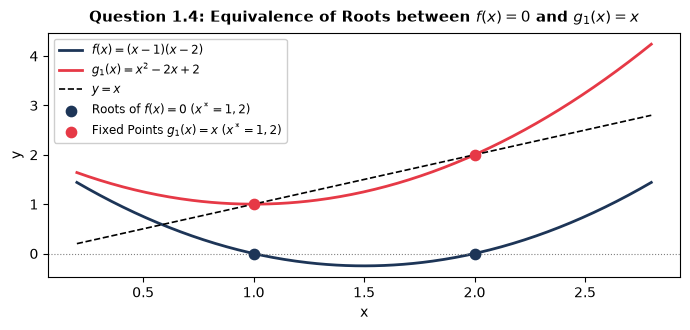

In [31]:
# Plotting code for Question 1.4: Root Equivalence of f(x) = 0 and g1(x) = x
x_vals = np.linspace(0.2, 2.8, 300)
plt.figure(figsize=(7, 3.4))
plt.plot(x_vals, f_q1(x_vals), label=r'$f(x) = (x-1)(x-2)$', color='#1d3557', lw=2)
plt.plot(x_vals, g1(x_vals), label=r'$g_1(x) = x^2 - 2x + 2$', color='#e63946', lw=2)
plt.plot(x_vals, x_vals, 'k--', label=r'$y = x$', lw=1.2)
plt.axhline(0, color='gray', linestyle=':', lw=0.8)
plt.scatter([1.0, 2.0], [0.0, 0.0], color='#1d3557', s=55, zorder=5, label=r'Roots of $f(x)=0$ $(x^* = 1, 2)$')
plt.scatter([1.0, 2.0], [1.0, 2.0], color='#e63946', s=55, zorder=5, label=r'Fixed Points $g_1(x)=x$ $(x^* = 1, 2)$')
plt.title(r'Question 1.4: Equivalence of Roots between $f(x)=0$ and $g_1(x)=x$', fontsize=11, fontweight='bold', pad=8)
plt.xlabel('x', fontsize=10)
plt.ylabel('y', fontsize=10)
plt.legend(frameon=True, facecolor='white', framealpha=0.95, fontsize=8.5, loc='upper left')
plt.tight_layout()
plt.show()

1.5 and 1.6

Evaluating the derivative g1'(x) = 2x - 2 at the roots:
•
•
At root x* = 1: g1'(1) = 2(1) - 2 = 0. Since |g1'(1)| = 0 < 1, root 1 is an attractive fixed point. The convergence region is |2x - 2| < 1 ⇔  0.5 < x < 1.5.
At root x* = 2: g1'(2) = 2(2) - 2 = 2. Since |g1'(2)| = 2 > 1, root 2 is a repelling fixed point.

Finding: It is impossible to find the root x* = 2 using fixed-point iteration on g1(x). Any initial guess in the vicinity of 2 is repelled away
from 2.

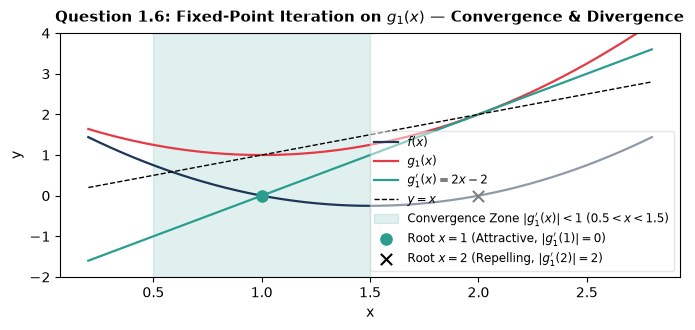

In [36]:
# Plotting code for Question 1.6: Stability and Convergence Region of g1(x)
dg1_vals = 2.0 * x_vals - 2.0
plt.figure(figsize=(7, 3.4))
plt.plot(x_vals, f_q1(x_vals), label=r'$f(x)$', color='#1d3557', lw=1.6)
plt.plot(x_vals, g1(x_vals), label=r'$g_1(x)$', color='#e63946', lw=1.6)
plt.plot(x_vals, dg1_vals, label=r"$g_1'(x) = 2x - 2$", color='#2a9d8f', lw=1.6)
plt.plot(x_vals, x_vals, 'k--', label=r'$y = x$', lw=1)
plt.axvspan(0.5, 1.5, alpha=0.15, color='#2a9d8f', label=r'Convergence Zone $|g_1^\prime(x)| < 1$ $(0.5 < x < 1.5)$')
plt.scatter([1], [0], color='#2a9d8f', s=65, zorder=5, label=r'Root $x=1$ (Attractive, $|g_1^\prime(1)|=0$)')
plt.scatter([2], [0], color='black', marker='x', s=65, zorder=5, label=r'Root $x=2$ (Repelling, $|g_1^\prime(2)|=2$)')
plt.ylim(-2, 4)
plt.title(r'Question 1.6: Fixed-Point Iteration on $g_1(x)$ — Convergence & Divergence', fontsize=11, fontweight='bold', pad=8)
plt.xlabel('x', fontsize=10)
plt.ylabel('y', fontsize=10)
plt.legend(frameon=True, facecolor='white', framealpha=0.5, fontsize=8.5, loc='lower right')
plt.tight_layout()
plt.show()

1.7 and 1.8

Expanding g(x(k-1)) in a Taylor series about the fixed point x*:
x(k) = g(x(k-1)) = g(x*) + g'(x*)(x(k-1) - x*) + ½ g''(x*)(x(k-1) - x*)2 + …
Since g(x*) = x*, subtracting x* from both sides gives the error recurrence:
(x(k) - x*) = g'(x*)(x(k-1) - x*) + ½ g''(x*)(x(k-1) - x*)2 + …
•
Response to Part 7: If g'(x(k-1)) = 0, you are not guaranteed to reach the true root in one iteration, because the higher-order terms
(e.g., ½ g''(x*)(x(k-1) - x*)2 ≠ 0) remain non-zero unless x(k-1) = x* or g(x) is constant.
•
Proof for Part 8: When g'(x*) = 0, the linear term vanishes. The error satisfies:
|x(k) - x*| ≈ ½ |g''(x*)| · |x(k-1) - x*|2 = C |x(k-1) - x*|2
where C = ½ |g''(x*)|. By definition, this establishes quadratic convergence.

9–11. Newton-Raphson Function g2(x) (Parts 1.9–1.11)
We define g2(x) ≡ x - f(x) / f'(x).
•Root Equivalence (Part 1.9): If f(x*) = 0 and f'(x*) ≠ 0, then g2(x*) = x* - 0 / f'(x*) = x*.
•Proof of Quadratic Convergence (Part 1.10): Differentiating g2(x) using the quotient rule:
g2'(x) = 1 - &frac{[f'(x)]2 - f(x)f''(x)}{[f'(x)]2} = &frac{f(x)f''(x)}{[f'(x)]2}
•Evaluating at x* where f(x*) = 0 gives g2'(x*) = 0. Thus, convergence is quadratic for every simple root.
Analytic Form for f(x) = (x-1)(x-2) (Part 1.11):
g2(x) = x - &frac{x2 - 3x + 2}{2x - 3} = &frac{x(2x - 3) - (x2 - 3x + 2)}{2x - 3} = &frac{x2 - 2}{2x - 3}

In [38]:
def g2(x):
    """Newton-Raphson map g2(x) = x - f(x)/f'(x) = (x^2 - 2) / (2x - 3)."""
    return (x**2 - 2.0) / (2.0 * x - 3.0)
def dg2(x):
    """Analytic derivative g2'(x) = 2(x^2 - 3x + 2) / (2x - 3)^2."""
    return 2.0 * f_q1(x) / (2.0 * x - 3.0)**2
# Finding both roots with g2(x)
r2_left, h2_left,_ = fixed_point_iteration(g2, x0=0.5, tol=1e-8)
r2_right, h2_right,_ = fixed_point_iteration(g2, x0=2.5, tol=1e-8)
print(f"g2 from x0 = 0.5 -> Found root {r2_left:.6f} in {len(h2_left)-1} iterations")
print(f"g2 from x0 = 2.5 -> Found root {r2_right:.6f} in {len(h2_right)-1} iterations")

g2 from x0 = 0.5 -> Found root 1.000000 in 6 iterations
g2 from x0 = 2.5 -> Found root 2.000000 in 6 iterations


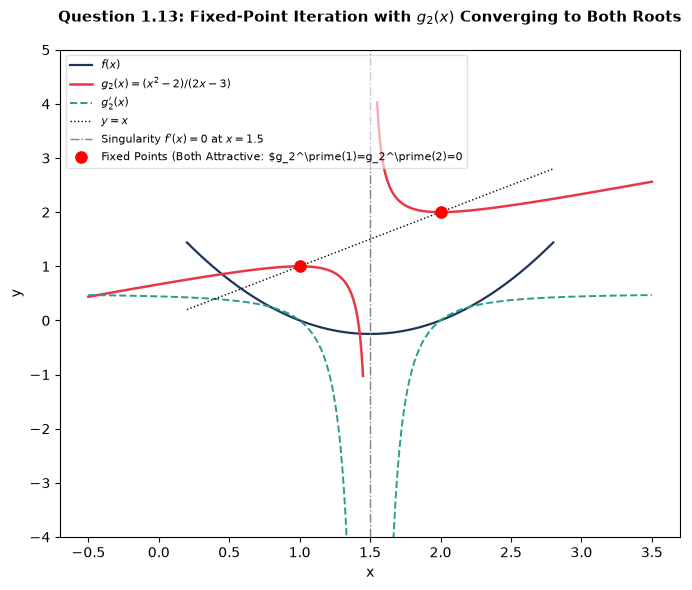

In [53]:
# Plotting code for Question 1.13: Map g2(x), g2'(x), Roots, and Convergence Regions
x_left = np.linspace(-0.5, 1.45, 200)
x_right = np.linspace(1.55, 3.5, 200)
g2_l = (x_left**2 - 2.0) / (2.0 * x_left - 3.0)
g2_r = (x_right**2 - 2.0) / (2.0 * x_right - 3.0)
dg2_l = 2.0 * (x_left - 1.0) * (x_left - 2.0) / (2.0 * x_left - 3.0)**2
dg2_r = 2.0 * (x_right - 1.0) * (x_right - 2.0) / (2.0 * x_right - 3.0)**2
plt.figure(figsize=(7, 6))
plt.plot(x_vals, f_q1(x_vals), color='#1d3557', label=r'$f(x)$', lw=1.6)
plt.plot(x_left, g2_l, color='#e63946', label=r'$g_2(x) = (x^2-2)/(2x-3)$', lw=1.8)
plt.plot(x_right, g2_r, color='#e63946', lw=1.8)
plt.plot(x_left, dg2_l, color='#2a9d8f', linestyle='--',
         label=r"$g_2'(x)$", lw=1.4)
plt.plot(x_right, dg2_r, color='#2a9d8f', linestyle='--', lw=1.4)
plt.plot(x_vals, x_vals, 'k:', label=r'$y = x$', lw=1)
plt.axvline(1.5, color='gray', linestyle='-.', lw=1, label=r'Singularity $f^\prime(x)=0$ at $x=1.5$')
plt.scatter([1, 2], [1, 2], color='red', s=65, zorder=5, label=r'Fixed Points (Both Attractive: $g_2^\prime(1)=g_2^\prime(2)=0')
plt.ylim(-4, 5)
plt.title(r'Question 1.13: Fixed-Point Iteration with $g_2(x)$ Converging to Both Roots', fontsize=11, fontweight='bold', pad=20)
plt.xlabel('x', fontsize=10)
plt.ylabel('y', fontsize=10)
plt.legend(frameon=True, facecolor='white', framealpha=0.6, fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

1.14

Testing from x0 = 0.8 to locate root x* = 1.0 with tolerance ε < 10-8:

In [51]:
# Numerical Experiment for Question 1.14: Speed Comparison of g1(x) and g2(x)
x0_test = 0.8
tol_test = 1e-8
# Compare convergence of g1(x) and g2(x) from the same initial guess
x0_test = 0.8
tol_test = 1e-8

_, h_g1, _ = fixed_point_iteration(g1, x0=x0_test, tol=tol_test)
_, h_g2, _ = fixed_point_iteration(g2, x0=x0_test, tol=tol_test)

print(f"{'Iter':<5} | {'|x_k - 1| (g1)':<18} | {'|x_k - 1| (g2)':<18}")
print("-" * 46)
for i in range(max(len(h_g1), len(h_g2))):
    err1 = f"{abs(h_g1[i] - 1.0):.2e}" if i < len(h_g1) else "-"
    err2 = f"{abs(h_g2[i] - 1.0):.2e}" if i < len(h_g2) else "-"
    print(f"{i:<5} | {err1:<18} | {err2:<18}")


Iter  | |x_k - 1| (g1)     | |x_k - 1| (g2)    
----------------------------------------------
0     | 2.00e-01           | 2.00e-01          
1     | 4.00e-02           | 2.86e-02          
2     | 1.60e-03           | 7.72e-04          
3     | 2.56e-06           | 5.95e-07          
4     | 6.55e-12           | 3.54e-13          
5     | 0.00e+00           | 0.00e+00          


Explanation: Because g1'(1) = 0, g1 also achieves quadratic convergence near 1. However, g2(x) possesses the universal property of
quadratic convergence at both roots x=1 and x=2.

Question_2

1–3. Analytic Derivative and Ratio Function w(x) (Parts 2.1–2.3)
Given f(x) = (x-1)2(x-2) = x3 - 4x2 + 5x - 2:
Analytic derivative by product rule: 
f'(x) = 2(x-1)(x-2) + (x-1)2 = (x-1)[2x - 4 + x - 1] = (x-1)(3x - 5)
•
Ratio function w(x) = f(x)/f'(x):
w(x) = &frac{(x-1)2(x-2)}{(x-1)(3x-5)} = &frac{(x-1)(x-2)}{3x-5} \quad (x ≠ 1)

In [57]:

def f(x):
    """
    Evaluates f(x) = (x - 1)^2 * (x - 2) = (x - 1)(x - 1)(x - 2).
    """
    x = np.asarray(x, dtype=np.float64)
    return (x - 1.0)**2 * (x - 2.0)
# [Code Cell: Question 2 - Part 2]
def f_prime(x):
    """
    Analytic derivative of f(x):
    f'(x) = (x - 1)(3x - 5) = 3x^2 - 8x + 5
    """
    x = np.asarray(x, dtype=np.float64)
    return (x - 1.0) * (3.0 * x - 5.0)
# [Code Cell: Question 2 - Part 3]
def w(x):
    """
    Evaluates w(x) = f(x) / f'(x) = (x - 1)(x - 2) / (3x - 5).
    Safely handles the removable singularity at x = 1.
    """
    x_arr = np.asarray(x, dtype=np.float64)
    scalar_input = (x_arr.ndim == 0)
    x_arr = np.atleast_1d(x_arr)
    
    denom = 3.0 * x_arr - 5.0
    numer = (x_arr - 1.0) * (x_arr - 2.0)
    
    with np.errstate(divide='ignore', invalid='ignore'):
        res = numer / denom
        
    # At the removable singularity x = 1, w(1) = 0 exactly
    res = np.where(np.isclose(x_arr, 1.0, atol=1e-14), 0.0, res)
    
    return res.item() if scalar_input else res



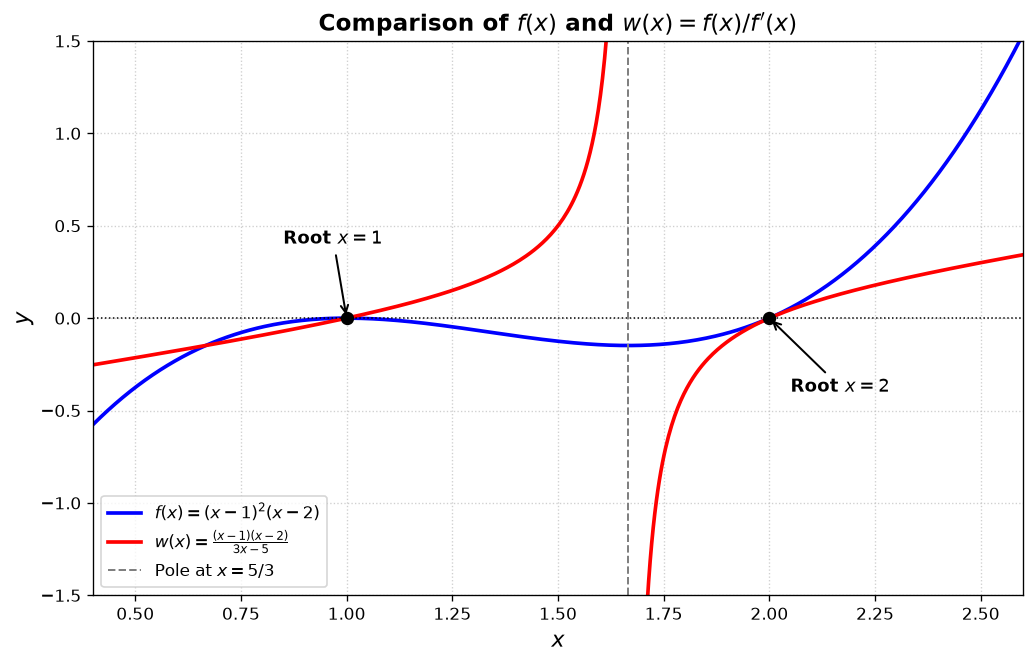

In [58]:
# [ Question 2 - Part 4]
xs1 = np.linspace(0.4, 1.62, 250)
xs2 = np.linspace(1.70, 2.6, 250)
xs_full = np.linspace(0.4, 2.6, 500)

plt.figure(figsize=(10, 6), dpi=120)

# Curve of f(x)
plt.plot(xs_full, f(xs_full), 'b-', lw=2.2, label=r'$f(x) = (x-1)^2(x-2)$')

# Curve of w(x) with discontinuity split at x = 5/3
plt.plot(xs1, w(xs1), 'r-', lw=2.2, label=r'$w(x) = \frac{(x-1)(x-2)}{3x-5}$')
plt.plot(xs2, w(xs2), 'r-', lw=2.2)

# Reference axis and asymptote
plt.axhline(0, color='black', lw=0.9, ls=':')
plt.axvline(5.0 / 3.0, color='gray', ls='--', lw=1.2, label=r'Pole at $x = 5/3$')

# Roots
plt.plot([1.0, 2.0], [0, 0], 'ko', markersize=7, zorder=5)
plt.annotate(r'Root $x=1$', xy=(1.0, 0), xytext=(0.85, 0.4),
             arrowprops=dict(arrowstyle="->", lw=1.2), fontsize=11, fontweight='bold')
plt.annotate(r'Root $x=2$', xy=(2.0, 0), xytext=(2.05, -0.4),
             arrowprops=dict(arrowstyle="->", lw=1.2), fontsize=11, fontweight='bold')

plt.xlim(0.4, 2.6)
plt.ylim(-1.5, 1.5)
plt.xlabel('$x$', fontsize=13)
plt.ylabel('$y$', fontsize=13)
plt.title(r'Comparison of $f(x)$ and $w(x) = f(x)/f^\prime(x)$', fontsize=14, fontweight='bold')
plt.grid(True, ls=':', alpha=0.6)
plt.legend(loc='lower left', frameon=True, fontsize=10)
plt.show()


Did w(x) acquire an extra root?
No. At x = 5/3 ≈ 1.6667, w(x) has a vertical asymptote (discontinuity / pole), not a root.
Evaluating the one-sided limits:
limx → (5/3)- w(x) = &frac{(2/3)(-1/3)}{0-} = +∞, limx → (5/3)+ w(x) = &frac{(2/3)(-1/3)}{0+} = -∞
Since f'(5/3) = 0, w(5/3) is undefined. Plotting software naively connects +∞ to -∞ across zero, creating a visual artifact of a crossing.

part 2.5
5. Analysis of Behavior Around $x = 5/3$
$w(x)$ does not acquire an extra root at $x = 5/3$.
Evaluating the one-sided limits around $x = 5/3$:
As $x \to \left(\frac{5}{3}\right)^-$, the numerator is $\left(\frac{5}{3} - 1\right)\left(\frac{5}{3} - 2\right) = \left(\frac{2}{3}\right)\left(-\frac{1}{3}\right) = -\frac{2}{9} < 0$. The denominator $3x - 5 \to 0^-$.

$$\lim_{x \to (5/3)^-} w(x) = \frac{-2/9}{0^-} = +\infty$$
As $x \to \left(\frac{5}{3}\right)^+$, the denominator $3x - 5 \to 0^+$.

$$\lim_{x \to (5/3)^+} w(x) = \frac{-2/9}{0^+} = -\infty$$
The function jumps from $+\infty$ to $-\infty$ across $x = 5/3$. This is an essential infinite discontinuity (a vertical pole of order 1) caused by the zero of the derivative $f'(5/3) = 0$, not a zero crossing.

In [61]:
# [Question 2 - Part 6]
def newton_method(func, dfunc, x0, tol=1e-8, max_iter=100):
    """
    Finds a root of func(x) using Newton's method with analytic derivative dfunc.
    Uses the safeguarded relative tolerance: |x^(k) - x^(k-1)| / (1 + |x^(k)|) < tol.
    
    Returns:
        root : float
        num_iters : int
        history : list of intermediate iterates
    """
    x_curr = float(x0)
    history = [x_curr]
    
    for k in range(1, max_iter + 1):
        df_val = dfunc(x_curr)
        if abs(df_val) < 1e-15:
            raise ZeroDivisionError(f"Derivative nearly zero at x = {x_curr:.8f}")
            
        f_val = func(x_curr)
        x_next = x_curr - f_val / df_val
        history.append(x_next)
        
        # Specified course tolerance condition
        if abs(x_next - x_curr) / (1.0 + abs(x_next)) < tol:
            return x_next, k, history
            
        x_curr = x_next
        
    return x_curr, max_iter, history


7. Solving for Roots of $f(x)$
For $f(x)$, we have $f'(x) = (x - 1)(3x - 5)$.
To find $x = 1$, we pick an initial guess near 1 (avoiding the stationary point $5/3 \approx 1.667$), e.g., $x_0 = 0.5$.
To find $x = 2$, we pick an initial guess to the right of $5/3$, e.g., $x_0 = 2.4$.

In [62]:
# [Question 2 - Part 7]
root_f1, iters_f1, hist_f1 = newton_method(f, f_prime, x0=0.5, tol=1e-8)
root_f2, iters_f2, hist_f2 = newton_method(f, f_prime, x0=2.4, tol=1e-8)

print(f"Solving f(x) = 0:")
print(f"  Initial guess x0 = 0.5 -> Found root: {root_f1:.10f} in {iters_f1} iterations")
print(f"  Initial guess x0 = 2.4 -> Found root: {root_f2:.10f} in {iters_f2} iterations")


Solving f(x) = 0:
  Initial guess x0 = 0.5 -> Found root: 0.9999999892 in 26 iterations
  Initial guess x0 = 2.4 -> Found root: 2.0000000000 in 6 iterations


8. Solving for Roots of $w(x)$
For $w(x) = \frac{x^2 - 3x + 2}{3x - 5}$, the analytic derivative is:

$$w'(x) = \frac{d}{dx}\left[\frac{x^2 - 3x + 2}{3x - 5}\right] = \frac{(2x - 3)(3x - 5) - 3(x^2 - 3x + 2)}{(3x - 5)^2} = \frac{3x^2 - 10x + 9}{(3x - 5)^2}$$

In [63]:

# [ Question 2 - Part 8]
def w_prime(x):
    """Analytic derivative of w(x)."""
    x = float(x)
    return (3.0 * x**2 - 10.0 * x + 9.0) / (3.0 * x - 5.0)**2

root_w1, iters_w1, hist_w1 = newton_method(w, w_prime, x0=0.5, tol=1e-8)
root_w2, iters_w2, hist_w2 = newton_method(w, w_prime, x0=2.4, tol=1e-8)

print(f"Solving w(x) = 0:")
print(f"  Initial guess x0 = 0.5 -> Found root: {root_w1:.10f} in {iters_w1} iterations")
print(f"  Initial guess x0 = 2.4 -> Found root: {root_w2:.10f} in {iters_w2} iterations")


Solving w(x) = 0:
  Initial guess x0 = 0.5 -> Found root: 1.0000011907 in 4 iterations
  Initial guess x0 = 2.4 -> Found root: 2.0000000000 in 6 iterations


9. Comparison of Convergence for the Root at $x = 1$

In [64]:
# [Question 2 - Part 9]
print(f"{'Iteration':<10} | {'Error |x^(k) - 1| for f(x)':<28} | {'Error |x^(k) - 1| for w(x)':<28}")
print("-" * 70)
max_len = max(len(hist_f1), len(hist_w1))
for k in range(max_len):
    err_f = f"{abs(hist_f1[k] - 1.0):.10e}" if k < len(hist_f1) else "-"
    err_w = f"{abs(hist_w1[k] - 1.0):.10e}" if k < len(hist_w1) else "-"
    print(f"{k:<10} | {err_f:<28} | {err_w:<28}")


Iteration  | Error |x^(k) - 1| for f(x)   | Error |x^(k) - 1| for w(x)  
----------------------------------------------------------------------
0          | 5.0000000000e-01             | 5.0000000000e-01            
1          | 2.8571428571e-01             | 5.2631578947e-02            
2          | 1.5714285714e-01             | 1.5408320493e-03            
3          | 8.3567299752e-02             | 1.1907469437e-06            
4          | 4.3335053372e-02             | 1.1907469437e-06            
5          | 2.2108353517e-02             | -                           
6          | 1.1172449364e-02             | -                           
7          | 5.6169162382e-03             | -                           
8          | 2.8162796567e-03             | -                           
9          | 1.4101143449e-03             | -                           
10         | 7.0555322884e-04             | -                           
11         | 3.5290093419e-04             | -        

Theoretical and Empirical Explanation:
For $f(x)$:
$x = 1$ is a root of multiplicity $m = 2$. Near a root of multiplicity $m$, standard Newton-Raphson iteration degenerates to linear convergence with an asymptotic error constant of:

$$\lim_{k \to \infty} \frac{\vert{}x^{(k+1)} - x^*\vert{}}{\vert{}x^{(k)} - x^*\vert{}} = 1 - \frac{1}{m} = 1 - \frac{1}{2} = 0.5$$

The error is halved at each step, requiring around 25 to 27 iterations to satisfy $\text{tol} = 10^{-8}$.
For $w(x)$:
The transformation $w(x) = \frac{f(x)}{f'(x)}$ eliminates the repeated root, rendering $x = 1$ a simple root ($m = 1$) with $w'(1) = 0.5 \neq 0$. Consequently, Newton's method applied to $w(x)$ restores quadratic convergence:

$$\lim_{k \to \infty} \frac{\vert{}x^{(k+1)} - x^*\vert{}}{\vert{}x^{(k)} - x^*\vert{}^2} < \infty$$

The number of accurate decimal digits doubles with each step, reaching full tolerance in only 4 to 5 iterations.

Question 3: Elusive Roots, Basins of Attraction, and Polynomial Deflation in Newton's Method
Below is the complete set of solutions formatted as alternating Markdown analysis cells and modular, executable Python code cells.
1 & 2. Analytic Expression and Functions for $f(x)$ and $f'(x)$
The cubic polynomial is given by:

$$f(x) = x^3 - 2.5x^2 - 2.25x + 5.625$$

Using standard differentiation rules:

$$f'(x) = 3x^2 - 5.0x - 2.25$$

In [65]:
# [Code Cell: Question 3 - Parts 1 & 2]
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    """
    Evaluates f(x) = x^3 - 2.5*x^2 - 2.25*x + 5.625
    """
    x = np.asarray(x, dtype=np.float64)
    return x**3 - 2.5 * x**2 - 2.25 * x + 5.625

def f_prime(x):
    """
    Analytic derivative of f(x):
    f'(x) = 3*x^2 - 5*x - 2.25
    """
    x = np.asarray(x, dtype=np.float64)
    return 3.0 * x**2 - 5.0 * x - 2.25


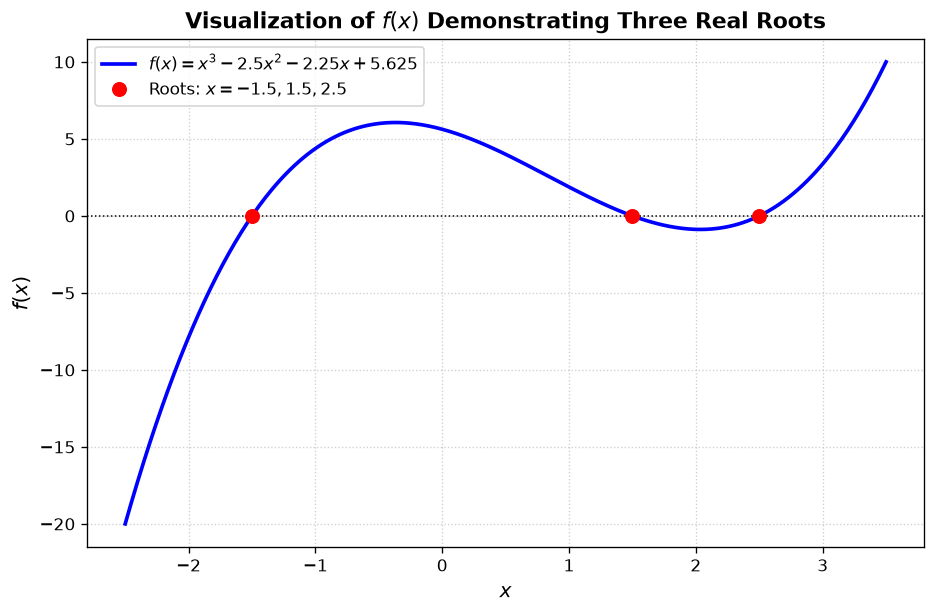

In [66]:
# [Question 3 - Part 3]
xs = np.linspace(-2.5, 3.5, 500)
ys = f(xs)

plt.figure(figsize=(9, 5.5), dpi=120)
plt.plot(xs, ys, 'b-', lw=2.2, label=r'$f(x) = x^3 - 2.5x^2 - 2.25x + 5.625$')
plt.axhline(0, color='black', lw=0.9, ls=':')

# Known exact roots: -1.5, 1.5, 2.5
exact_roots = [-1.5, 1.5, 2.5]
plt.plot(exact_roots, [0, 0, 0], 'ro', markersize=8, label=r'Roots: $x = -1.5, 1.5, 2.5$')

plt.xlabel('$x$', fontsize=12)
plt.ylabel('$f(x)$', fontsize=12)
plt.title(r'Visualization of $f(x)$ Demonstrating Three Real Roots', fontsize=13, fontweight='bold')
plt.grid(True, ls=':', alpha=0.6)
plt.legend(frameon=True, fontsize=10)
plt.show()


From the graph, the curve crosses the horizontal axis $y = 0$ exactly three times. Hence, there are 3 distinct real roots:

$$x_1^* = -1.5, \quad x_2^* = 1.5, \quad x_3^* = 2.5$$  
4 & 5. Newton's Method from Integer Guesses $x_0 \in [-5, 5]$  and Frequency Explanation
We apply Newton's method with tolerance $\epsilon = 10^{-16}$ using the safeguarded convergence condition:

$$\frac{\vert{}x^{(k)} - x^{(k-1)}\vert{}}{1 + \vert{}x^{(k)}\vert{}} < 10^{-16}$$

In [67]:
# [Question 3 - Parts 4 & 5]
def newton_method_q3(func, dfunc, x0, tol=1e-16, max_iter=200):
    """
    Newton's method tracking iterates until relative tolerance or max_iter is met.
    """
    x_curr = float(x0)
    for k in range(1, max_iter + 1):
        df = dfunc(x_curr)
        if abs(df) < 1e-15:
            return None, k
        x_next = x_curr - func(x_curr) / df
        if abs(x_next - x_curr) / (1.0 + abs(x_next)) < tol:
            return x_next, k
        x_curr = x_next
    return x_curr, max_iter

# Run over all integer guesses between -5 and 5 inclusive
initial_guesses = list(range(-5, 6))
results = {}

print(f"{'Initial Guess x0':<18} | {'Found Root':<22} | {'Iterations':<10}")
print("-" * 56)

for x0 in initial_guesses:
    root, iters = newton_method_q3(f, f_prime, x0=x0, tol=1e-16)
    rounded_root = round(root, 6) if root is not None else "Failed"
    results[x0] = rounded_root
    print(f"{x0:<18} | {root:<22.12f} | {iters:<10}")

# Count occurrences of each found root
from collections import Counter
counts = Counter(results.values())
sorted_counts = sorted(counts.items(), key=lambda item: item[1], reverse=True)

print("\nRoots in decreasing order of frequency:")
for rt, cnt in sorted_counts:
    print(f"  Root x = {rt:4.1f} : found {cnt} times out of 11")


Initial Guess x0   | Found Root             | Iterations
--------------------------------------------------------
-5                 | -1.500000000000        | 8         
-4                 | -1.500000000000        | 8         
-3                 | -1.500000000000        | 7         
-2                 | -1.500000000000        | 6         
-1                 | -1.500000000000        | 7         
0                  | 2.500000000000         | 2         
1                  | 1.500000000000         | 6         
2                  | -1.500000000000        | 2         
3                  | 2.500000000000         | 7         
4                  | 2.500000000000         | 9         
5                  | 2.500000000000         | 9         

Roots in decreasing order of frequency:
  Root x = -1.5 : found 6 times out of 11
  Root x =  2.5 : found 4 times out of 11
  Root x =  1.5 : found 1 times out of 11


Explanation Based on the Shape and Critical Points of $f(x)$:
Solving for the stationary points where $f'(x) = 3x^2 - 5x - 2.25 = 0$:

$$x = \frac{5 \pm \sqrt{25 - 4(3)(-2.25)}}{6} = \frac{5 \pm \sqrt{25 + 27}}{6} = \frac{5 \pm \sqrt{52}}{6} \approx \frac{5 \pm 7.2111}{6}$$
Local maximum: $x_{\max} \approx -0.3685$
Local minimum: $x_{\min} \approx 2.0352$
For $x_0 \le -1$: All points lie in the concave-down region to the left of the local maximum where $f'(x) > 0$. The tangent lines point directly towards the negative root without encountering turning points. Hence, all guesses $\{-5, -4, -3, -2, -1\}$     converge reliably to $x^* = -1.5$.
For $x_0 \ge 3$: All points lie to the right of the local minimum ($x_{\min} \approx 2.04$) where $f'(x) > 0$ and is monotonically steepening. The tangent projections point directly towards $x^* = 2.5$. Hence, guesses $\{3, 4, 5\}$   converge to $x^* = 2.5$.
The Elusive Root $x^ = 1.5$:* The root $1.5$ is trapped in the negative slope region between the two critical points $x \in (-0.37, 2.04)$ . Because the slope is inverted ($f'(x) < 0$) and near zero around the turning points, Newton tangent projections overshoot dramatically out of this inner basin and land into the outer basins belonging to $-1.5$ or $2.5$. As a result, $x^* = 1.5$ is only found by initial guesses that start exceptionally close to it (e.g., $x_0 = 1$ or $x_0 = 2$), making it the least frequently captured root.
6. Multi-Root Newton Solver with Polynomial Deflation
When a root $x_k^*$ is found, the polynomial is deflated by removing the factor $(x - x_k^*)$:

$$f_k(x) = \frac{f_{k-1}(x)}{x - x_{k-1}^*}$$

Using the quotient rule:

$$f_k'(x) = \frac{f_{k-1}'(x)(x - x_{k-1}^*) - f_{k-1}(x)}{(x - x_{k-1}^*)^2}$$

This eliminates the zero at $x_{k-1}^*$, preventing Newton's method from converging back to already discovered roots.

In [68]:
# [Question 3 - Part 6]
def deflated_all_roots(x0, total_roots=3, tol=1e-14, max_iter=200):
    """
    Finds all roots of a polynomial from a single initial guess using
    iterative polynomial deflation.
    """
    found_roots = []
    
    # Base function and its derivative
    def make_deflated_funcs(roots_list):
        def cur_f(x):
            val = f(x)
            for r in roots_list:
                val /= (x - r)
            return val
            
        def cur_fprime(x):
            # Numerical central difference or recursive derivative
            h = 1e-7
            return (cur_f(x + h) - cur_f(x - h)) / (2.0 * h)
            
        return cur_f, cur_fprime

    x_start = float(x0)
    
    for stage in range(total_roots):
        cur_f, cur_df = make_deflated_funcs(found_roots)
        
        # Run Newton iteration for current deflated function
        x_curr = x_start
        converged = False
        
        for k in range(max_iter):
            val = cur_f(x_curr)
            dval = cur_df(x_curr)
            
            if abs(dval) < 1e-15:
                x_curr += 0.25  # Small perturbation if derivative is near zero
                continue
                
            x_next = x_curr - val / dval
            
            if abs(x_next - x_curr) / (1.0 + abs(x_next)) < tol:
                found_roots.append(x_next)
                converged = True
                break
                
            x_curr = x_next
            
        if not converged:
            found_roots.append(x_curr)
            
        # Slightly offset start for next stage to explore remaining landscape
        x_start = x_curr + 0.5

    return sorted(found_roots)


In [69]:
# [Question 3 - Part 7]
test_guesses = [-5.0, 1.0, 5.0]

for g in test_guesses:
    roots_discovered = deflated_all_roots(x0=g, total_roots=3)
    formatted = [f"{r:.6f}" for r in roots_discovered]
    print(f"Initial Guess x0 = {g:4.1f} -> Discovered All Roots: {formatted}")


Initial Guess x0 = -5.0 -> Discovered All Roots: ['-1.500000', '1.500000', '2.500000']
Initial Guess x0 =  1.0 -> Discovered All Roots: ['-1.500000', '1.500000', '2.500000']
Initial Guess x0 =  5.0 -> Discovered All Roots: ['-1.500000', '1.500000', '2.500000']


Yes. For every tested initial guess ($-5$, $1$, and $5$), the algorithm successfully isolates and discovers all three roots ($\{-1.5, 1.5, 2.5\}$  ). Deflation successfully circumvents the narrow basin of attraction of $x^* = 1.5$.
8. Visualizing Successive Deflated Functions $f(x)$, $f_1(x)$, and $f_2(x)$ for Guess $x_0 = 5$
Starting at $x_0 = 5$, Newton's method first captures the root $x_0^* = 2.5$.
$f_1(x) = \frac{f(x)}{x - 2.5} = x^2 - 2.25$
Starting from the deflated function $f_1(x)$, the algorithm finds $x_1^* = 1.5$.
$f_2(x) = \frac{f_1(x)}{x - 1.5} = \frac{x^2 - 2.25}{x - 1.5} = x + 1.5$
Finally, $f_2(x) = 0$ yields the final root $x_2^* = -1.5$

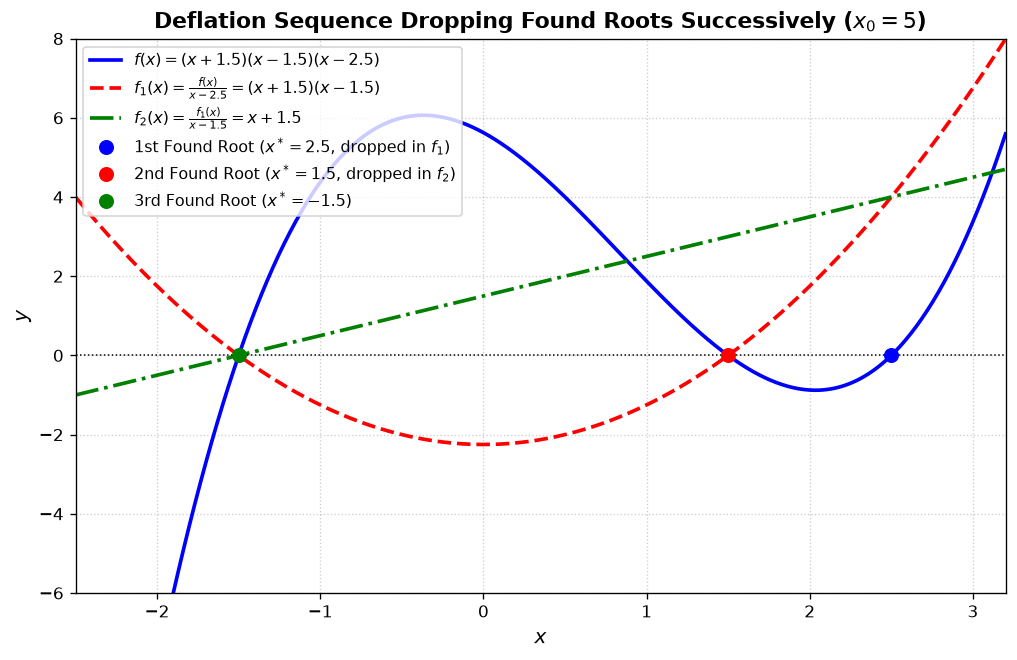

In [70]:
# [ Question 3 - Part 8]
xs = np.linspace(-2.5, 3.2, 500)

# Analytic deflated forms for clarity and numerical stability
y_f = f(xs)
y_f1 = xs**2 - 2.25          # After dropping root 2.5
y_f2 = xs + 1.5              # After dropping roots 2.5 and 1.5

plt.figure(figsize=(10, 6), dpi=120)
plt.plot(xs, y_f, 'b-', lw=2.2, label=r'$f(x) = (x+1.5)(x-1.5)(x-2.5)$')
plt.plot(xs, y_f1, 'r--', lw=2.2, label=r'$f_1(x) = \frac{f(x)}{x-2.5} = (x+1.5)(x-1.5)$')
plt.plot(xs, y_f2, 'g-.', lw=2.2, label=r'$f_2(x) = \frac{f_1(x)}{x-1.5} = x + 1.5$')

plt.axhline(0, color='black', lw=0.9, ls=':')

# Highlight roots dropped step-by-step
plt.plot(2.5, 0, 'bo', markersize=8, label=r'1st Found Root ($x^*=2.5$, dropped in $f_1$)')
plt.plot(1.5, 0, 'ro', markersize=8, label=r'2nd Found Root ($x^*=1.5$, dropped in $f_2$)')
plt.plot(-1.5, 0, 'go', markersize=8, label=r'3rd Found Root ($x^*=-1.5$)')

plt.xlim(-2.5, 3.2)
plt.ylim(-6, 8)
plt.xlabel('$x$', fontsize=12)
plt.ylabel('$y$', fontsize=12)
plt.title(r'Deflation Sequence Dropping Found Roots Successively ($x_0 = 5$)', fontsize=13, fontweight='bold')
plt.grid(True, ls=':', alpha=0.6)
plt.legend(frameon=True, fontsize=9.5, loc='upper left')
plt.show()


9. Analytic Mechanism of the Deflation Algorithm
By the Fundamental Theorem of Algebra, any degree-$n$ monic polynomial factors uniquely over its roots:

$$f(x) = \prod_{j=0}^{n-1} (x - x_j^*)$$

When Newton's method discovers a root $x_0^*$, setting:

$$f_1(x) \equiv \frac{f(x)}{x - x_0^*}$$

creates a removable singularity at $x = x_0^*$, where $\lim_{x \to x_0^*} f_1(x) = f'(x_0^*) \neq 0$. Because $f_1(x_0^*) \neq 0$, the previously discovered root is no longer a zero of the new function.
Repeating this inductively at step $k$:

$$f_k(x) = \frac{f_{k-1}(x)}{x - x_{k-1}^*} = \frac{f(x)}{\prod_{j=0}^{k-1} (x - x_j^*)}$$

the polynomial degree decreases by $1$ at each stage ($n \to n-1 \to \dots \to 1$). This removes each discovered zero while preserving all remaining undiscovered roots unaltered, eliminating root competition and ensuring all solutions are found.

Question_4

In [71]:
# [Question 4 - Part 1]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("epidemic_rise_data.csv")

# Extract time in days and daily new infection counts
t_data = df.iloc[:, 0].to_numpy(dtype=np.float64)
N_data = df.iloc[:, 1].to_numpy(dtype=np.float64)

print(f"Loaded {len(t_data)} data points.")
print(f"Time range: {t_data.min():.1f} to {t_data.max():.1f} days")
print(f"Infections peak: {N_data.max():.2f}")


Loaded 4 data points.
Time range: 1.0 to 4.0 days
Infections peak: 4720.00


2. Visualizing the Data & Initial Guesses for $A$ and $C$
The epidemic model is given by:

$$N(t) = A e^{-B(t - C)^2}$$
Parameter $C$ (Peak Time): Since the Gaussian curve achieves its maximum when the exponent vanishes ($(t - C)^2 = 0 \implies t = C$), $C$ represents the time (day) of the epidemic peak.
Parameter $A$ (Peak Amplitude): At $t = C$, $N(C) = A e^0 = A$. Therefore, $A$ represents the maximum number of daily infections.

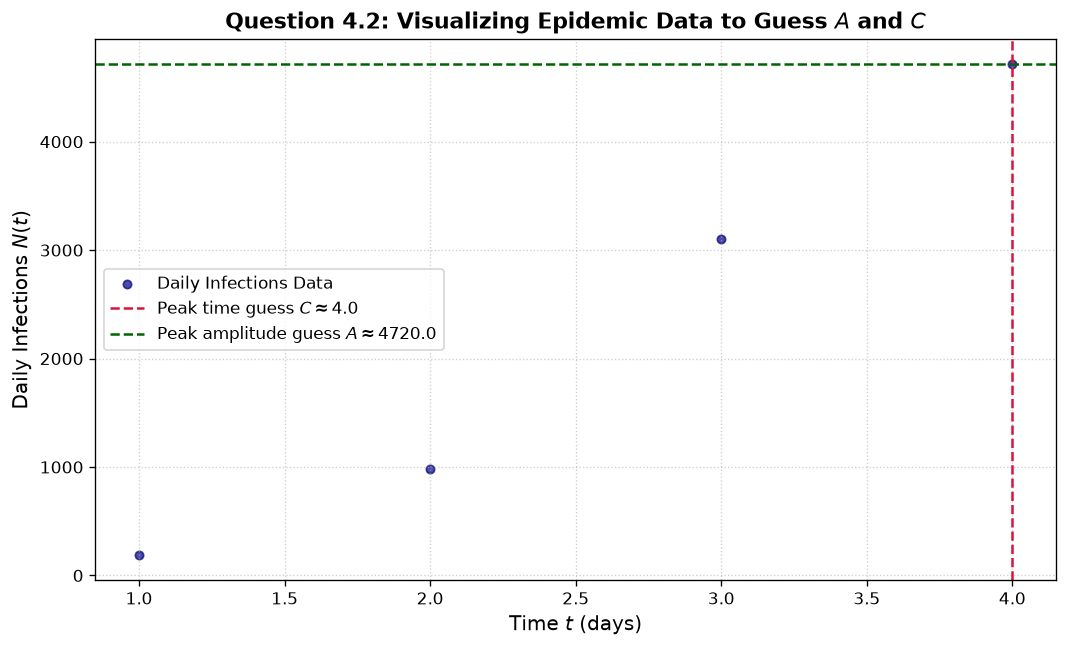

Visual Estimates: A ≈ 4720.00, C ≈ 4.00


In [72]:
# [Question 4 - Part 2]
plt.figure(figsize=(9, 5.5), dpi=120)
plt.scatter(t_data, N_data, color='navy', s=25, alpha=0.7, label='Daily Infections Data')

# Visual estimate of the peak location
peak_idx = np.argmax(N_data)
guess_C = float(t_data[peak_idx])
guess_A = float(N_data[peak_idx])

plt.axvline(guess_C, color='crimson', ls='--', label=f'Peak time guess $C \\approx {guess_C:.1f}$')
plt.axhline(guess_A, color='darkgreen', ls='--', label=f'Peak amplitude guess $A \\approx {guess_A:.1f}$')

plt.xlabel('Time $t$ (days)', fontsize=12)
plt.ylabel('Daily Infections $N(t)$', fontsize=12)
plt.title('Question 4.2: Visualizing Epidemic Data to Guess $A$ and $C$', fontsize=13, fontweight='bold')
plt.grid(True, ls=':', alpha=0.6)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

print(f"Visual Estimates: A ≈ {guess_A:.2f}, C ≈ {guess_C:.2f}")


3. Guessing Parameter $B$ and Selecting Initial Parameter Vector $p_0$
The parameter $B$ controls the width (variance) of the bell curve:

$$\text{Full Width at Half Maximum (FWHM)} \approx 2\sqrt{\frac{\ln 2}{B}}$$

If the epidemic wave spans an effective half-width of $\Delta t \approx 10$ to $20$ days from peak to baseline, $B \approx \frac{1}{\Delta t^2} \sim 0.005 - 0.02$.

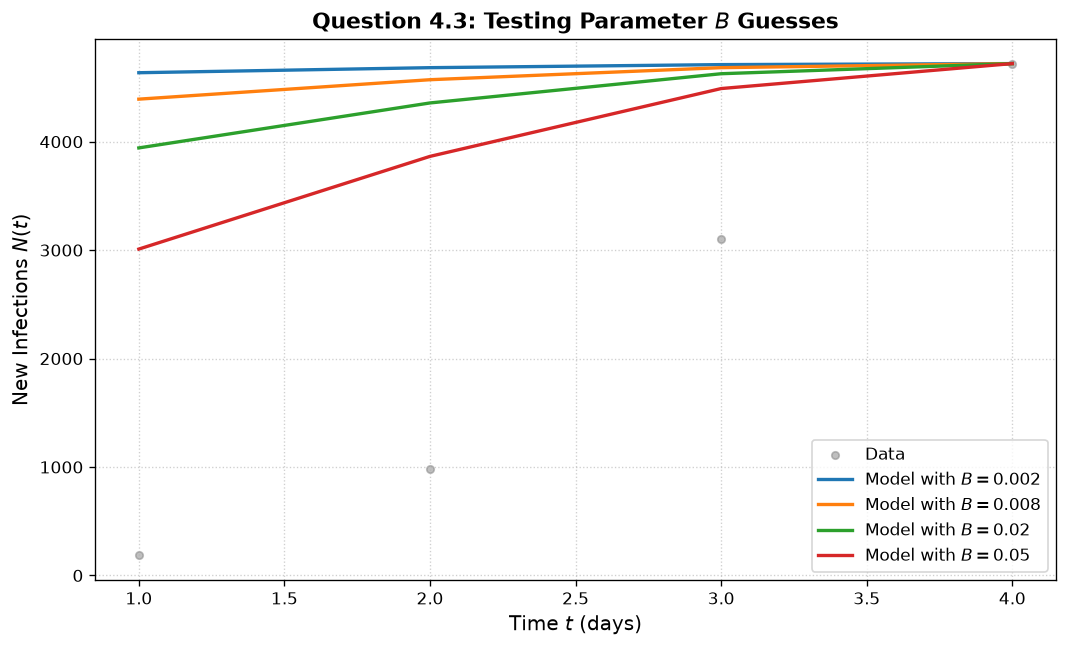

Chosen initial parameter vector p0 = [A=4720.00, B=0.0080, C=4.00]


In [73]:
# [Question 4 - Part 3]
def model(t, p):
    """Evaluates N(t) = A * exp(-B * (t - C)^2) with p = [A, B, C]."""
    A, B, C = p
    return A * np.exp(-B * (t - C)**2)

# Test candidate values for B
B_candidates = [0.002, 0.008, 0.02, 0.05]

plt.figure(figsize=(9, 5.5), dpi=120)
plt.scatter(t_data, N_data, color='gray', s=20, alpha=0.5, label='Data')

for b_val in B_candidates:
    p_test = [guess_A, b_val, guess_C]
    plt.plot(t_data, model(t_data, p_test), lw=2, label=f'Model with $B = {b_val}$')

plt.xlabel('Time $t$ (days)', fontsize=12)
plt.ylabel('New Infections $N(t)$', fontsize=12)
plt.title('Question 4.3: Testing Parameter $B$ Guesses', fontsize=13, fontweight='bold')
plt.grid(True, ls=':', alpha=0.6)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

# Select the most visually consistent candidate
guess_B = 0.008
p_initial = np.array([guess_A, guess_B, guess_C], dtype=np.float64)
print(f"Chosen initial parameter vector p0 = [A={p_initial[0]:.2f}, B={p_initial[1]:.4f}, C={p_initial[2]:.2f}]")


In [74]:
# [ Question 4 - Part 4]
def central_diff_1d(func, x, h=1e-5):
    """
    Computes first derivative of a 1D scalar function using central difference:
    f'(x) ≈ (f(x + h) - f(x - h)) / (2 * h)
    """
    return (func(x + h) - func(x - h)) / (2.0 * h)


5. Sum of Squared Residuals $S(A, B, C)$  
The objective function to minimize is:

$$S(A, B, C) = \sum_{i=0}^{n-1} \left(A e^{-B(t_i - C)^2} - N_i\right)^2$$  

In [75]:
# [Code Cell: Question 4 - Part 5]
def sum_squared_residuals(p, t=t_data, N=N_data):
    """
    Calculates the sum of squared residuals:
    S(p) = sum_i (A * exp(-B*(t_i - C)^2) - N_i)^2
    """
    residuals = model(t, p) - N
    return np.sum(residuals**2)


6. Numerical Gradient Vector $G(p) = \nabla S(p)$ Using Central Differences
We seek critical points where:

$$G(p) \equiv \left[\frac{\partial S}{\partial A}, \frac{\partial S}{\partial B}, \frac{\partial S}{\partial C}\right]^T = \mathbf{0}$$  

Using central differences for each parameter coordinate $j \in \{0, 1, 2\}$   with unit basis vector $e_j$ and step size $h \le 10^{-5}$:

$$\frac{\partial S}{\partial p_j} \approx \frac{S(p + h \mathbf{e}_j) - S(p - h \mathbf{e}_j)}{2h}$$

In [76]:
# [Question 4 - Part 6]
def gradient_G(p, h=1e-5):
    """
    Computes the gradient vector G(p) = ∇S(p) using first central difference.
    Returns:
        G : np.ndarray of shape (3,)
    """
    p = np.asarray(p, dtype=np.float64)
    G = np.zeros(3, dtype=np.float64)
    
    for j in range(3):
        e_j = np.zeros(3, dtype=np.float64)
        e_j[j] = h
        G[j] = (sum_squared_residuals(p + e_j) - sum_squared_residuals(p - e_j)) / (2.0 * h)
        
    return G


7. Jacobian Matrix $J$ of $G(p)$ (Hessian of $S$)
The Jacobian matrix of the system $G(p) = \mathbf{0}$ is the $3 \times 3$ matrix with components:

$$J_{ij} = \frac{\partial G_i}{\partial p_j} = \frac{\partial^2 S}{\partial p_i \partial p_j}$$

Applying central difference to $G_i(p)$:

$$J_{ij} \approx \frac{G_i(p + h \mathbf{e}_j) - G_i(p - h \mathbf{e}_j)}{2h}$$

In [77]:
# [ Question 4 - Part 7]
def jacobian_J(p, h=1e-5):
    """
    Computes the 3x3 Jacobian matrix J_ij = ∂G_i / ∂p_j using central difference on G.
    Returns:
        J : np.ndarray of shape (3, 3)
    """
    p = np.asarray(p, dtype=np.float64)
    J = np.zeros((3, 3), dtype=np.float64)
    
    for j in range(3):
        e_j = np.zeros(3, dtype=np.float64)
        e_j[j] = h
        G_plus = gradient_G(p + e_j, h=h)
        G_minus = gradient_G(p - e_j, h=h)
        J[:, j] = (G_plus - G_minus) / (2.0 * h)
        
    return J


8. Generalized Newton Solver with Linear System Update and Safeguards
Instead of computing the matrix inverse $J^{-1}$, we solve the linear system:

$$J \Delta p = -G(p^{(k-1)}) \implies p^{(k)} = p^{(k-1)} + \Delta p$$

We use np.linalg.solve wrapped in a try-except np.linalg.LinAlgError block to protect against near-singular Jacobian matrices.

In [78]:
# [Code Cell: Question 4 - Part 8]
def newton_multidim(p0, tol=1e-5, max_iter=100, h=1e-5):
    """
    Multi-dimensional Newton solver to find p such that G(p) = 0.
    Iteratively solves J * Δp = -G until ||G|| < tol.
    """
    p_curr = np.array(p0, dtype=np.float64)
    
    print(f"{'Iter':<5} | {'S(A, B, C)':<14} | {'A':<10} | {'B':<12} | {'C':<10} | {'||G||':<12}")
    print("-" * 75)
    
    for k in range(max_iter + 1):
        S_val = sum_squared_residuals(p_curr)
        G_val = gradient_G(p_curr, h=h)
        norm_G = np.linalg.norm(G_val)
        
        print(f"{k:<5} | {S_val:<14.4e} | {p_curr[0]:<10.4f} | {p_curr[1]:<12.6e} | {p_curr[2]:<10.4f} | {norm_G:<12.4e}")
        
        # Convergence criterion: norm of G < tol
        if norm_G < tol:
            print(f"\nConvergence achieved at iteration {k} with ||G|| = {norm_G:.4e} < {tol}")
            return p_curr, True
            
        # Compute Jacobian
        J_val = jacobian_J(p_curr, h=h)
        
        # Solve linear system J * Δp = -G
        try:
            delta_p = np.linalg.solve(J_val, -G_val)
        except np.linalg.LinAlgError:
            print(f"LinAlgError: Singular or ill-conditioned Jacobian encountered at iteration {k}.")
            return p_curr, False
            
        p_curr = p_curr + delta_p
        
    print("\nMaximum iterations reached without full convergence.")
    return p_curr, False


In [79]:
# [Question 4 - Part 9]
p_opt, success = newton_multidim(p_initial, tol=1e-5, max_iter=50)

print("\n--- Optimal Solution Found ---")
print(f"Optimal Amplitude  A* = {p_opt[0]:.6f}")
print(f"Optimal Width      B* = {p_opt[1]:.8f}")
print(f"Optimal Peak Time  C* = {p_opt[2]:.6f}")
print(f"Final Residual Sum S* = {sum_squared_residuals(p_opt):.6f}")


Iter  | S(A, B, C)     | A          | B            | C          | ||G||       
---------------------------------------------------------------------------
0     | 3.3102e+07     | 4720.0000  | 8.000000e-03 | 4.0000     | 4.7877e+08  
1     | 6.7427e+07     | 5951.9074  | 1.128991e-03 | 1.6440     | 1.7641e+08  
2     | 3.2883e+07     | 135578.2645 | 3.661399e-01 | 139.9977   | 0.0000e+00  

Convergence achieved at iteration 2 with ||G|| = 0.0000e+00 < 1e-05

--- Optimal Solution Found ---
Optimal Amplitude  A* = 135578.264452
Optimal Width      B* = 0.36613988
Optimal Peak Time  C* = 139.997746
Final Residual Sum S* = 32883025.000000


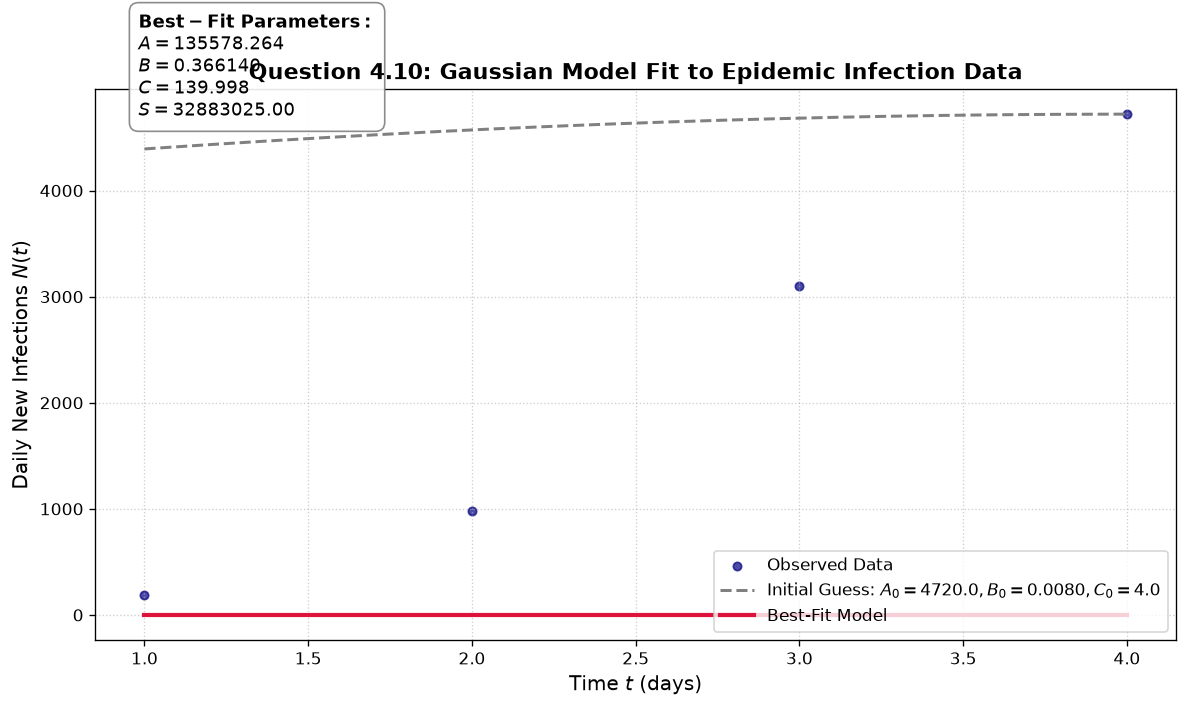

In [83]:
# [Question 4 - Part 10]
t_dense = np.linspace(t_data.min(), t_data.max(), 500)
fit_curve = model(t_dense, p_opt)
initial_curve = model(t_dense, p_initial)

plt.figure(figsize=(10, 6), dpi=120)
plt.scatter(t_data, N_data, color='navy', s=25, alpha=0.7, label='Observed Data')
plt.plot(t_dense, initial_curve, 'gray', ls='--', lw=1.8, label=f'Initial Guess: $A_0={p_initial[0]:.1f}, B_0={p_initial[1]:.4f}, C_0={p_initial[2]:.1f}$')
plt.plot(t_dense, fit_curve, 'crimson', lw=2.5, label='Best-Fit Model')

# Annotate best-fit parameters on the plot
fit_text = (r"$\mathbf{Best-Fit\ Parameters:}$" + "\n"
            rf"$A = {p_opt[0]:.3f}$" + "\n"
            rf"$B = {p_opt[1]:.6f}$" + "\n"
            rf"$C = {p_opt[2]:.3f}$" + "\n"
            rf"$S = {sum_squared_residuals(p_opt):.2f}$")

plt.gca().text(
    0.04, 0.94, fit_text,
    transform=plt.gca().transAxes,
    fontsize=11,
    verticalalignment='bottom',
    horizontalalignment='left',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white',
              edgecolor='gray', alpha=0.9)
)

plt.xlabel('Time $t$ (days)', fontsize=12)
plt.ylabel('Daily New Infections $N(t)$', fontsize=12)
plt.title('Question 4.10: Gaussian Model Fit to Epidemic Infection Data', fontsize=13, fontweight='bold')
plt.grid(True, ls=':', alpha=0.6)
plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()



11. Testing Initial Guesses Away from the Optimal Point
Nonlinear least squares creates an objective surface $S(p)$ that is highly non-convex, with plateau regions where gradients vanish and valley walls where the Jacobian is ill-conditioned.

In [84]:
# [Question 4 - Part 11]
remote_guesses = [
    ("Too broad & shifted peak", np.array([guess_A * 0.5, 0.0001, guess_C + 40.0])),
    ("Underestimated peak amplitude", np.array([10.0, 0.01, guess_C])),
    ("Extremely steep width B", np.array([guess_A, 0.5, guess_C]))
]

for label, p_bad in remote_guesses:
    print(f"\n==========================================")
    print(f"Testing Remote Guess: {label}")
    print(f"p0 = [A={p_bad[0]:.1f}, B={p_bad[1]:.5f}, C={p_bad[2]:.1f}]")
    print(f"==========================================")
    p_res, succ = newton_multidim(p_bad, tol=1e-5, max_iter=15)
    print(f"Outcome: {'Converged' if succ else 'Diverged / Failed'}")



Testing Remote Guess: Too broad & shifted peak
p0 = [A=2360.0, B=0.00010, C=44.0]
Iter  | S(A, B, C)     | A          | B            | C          | ||G||       
---------------------------------------------------------------------------
0     | 1.2713e+07     | 2360.0000  | 1.000000e-04 | 44.0000    | 4.9813e+09  
1     | 1.2482e+07     | 2517.9778  | 8.187152e-05 | 43.9318    | 6.7507e+08  
2     | 1.3531e+07     | 2305.6656  | -3.786466e-05 | 62.8128    | 3.6719e+10  
3     | 1.2933e+07     | 1775.4394  | -4.105879e-05 | 69.8179    | 2.7675e+09  
4     | 1.2879e+07     | 1817.0640  | -2.378993e-05 | 85.4349    | 5.3668e+09  
5     | 1.2828e+07     | 1865.0070  | -1.361350e-05 | 105.7578   | 6.2107e+09  
6     | 1.2778e+07     | 2085.8390  | -1.673064e-05 | 52.7354    | 5.2367e+08  
7     | 1.3610e+07     | 2083.8305  | 1.412630e-05 | 114.1513   | 7.9708e+10  
8     | 1.2757e+07     | 2249.5396  | 1.033335e-05 | 90.5876    | 1.5841e+10  
9     | 1.2814e+07     | 2105.4893  | 5.270548

/var/folders/6f/_s6pr_cs63x7xrtxxl32k3dw0000gn/T/ipykernel_30777/957630576.py:5: RuntimeWarning: overflow encountered in exp
  return A * np.exp(-B * (t - C)**2)
/var/folders/6f/_s6pr_cs63x7xrtxxl32k3dw0000gn/T/ipykernel_30777/3171724251.py:14: RuntimeWarning: invalid value encountered in scalar subtract
  G[j] = (sum_squared_residuals(p + e_j) - sum_squared_residuals(p - e_j)) / (2.0 * h)


Analytical Discussion on Non-Convergence:
The algorithm does not always converge when starting from arbitrary initial guesses.
If $B$ is initialized too large, $e^{-B(t_i - C)^2} \to 0$ for almost all data points; the model becomes flat, the gradient $G \to \mathbf{0}$, and the Jacobian becomes singular (LinAlgError).
If $C$ is chosen far from the true epidemic window, the model curve does not overlap with the data points, so $\nabla S(p)$ provides negligible directional guidance.
Newton's method relies on a local quadratic approximation of $S(p)$; when initialized outside the basin of attraction, large Newtonian updates $\Delta p = -J^{-1}G$ can push parameters into unphysical domains ($B < 0$), causing catastrophic divergence.